## 0. Setup Awal

In [1]:
import os
import time
import tracemalloc
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings('ignore')

plt.style.use(
    'seaborn-v0_8-whitegrid'
    if 'seaborn-v0_8-whitegrid' in plt.style.available
    else 'default'
)

plt.rcParams['figure.dpi'] = 120

OUTPUT_DIR = 'outputNBAntiBurnoutMultinomial'
os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

## 1. Data Understanding

### 1.1 Load Dataset

In [2]:
df = pd.read_csv('burnout_dataset1.csv')

print(f'Jumlah data awal: {len(df)}')

# df = df.sample(
#     n=5000,
#     random_state=42
# ).reset_index(drop=True)
# print(f'Jumlah data setelah sampling: {len(df)}')

Jumlah data awal: 50000


### 1.2 Identifikasi Kolom yang Digunakan

In [3]:
numeric_columns = df.select_dtypes(
    include='number'
).columns

categorical_columns = df.select_dtypes(
    include=['object', 'category']
).columns

print('Kolom Numerik:')
print(
    numeric_columns.tolist()
)

print(
    '\nKolom Kategorikal:'
)
print(
    categorical_columns.tolist()
)

Kolom Numerik:
['Person_ID', 'Age', 'Monthly_Income_USD', 'Work_Hours_Per_Week', 'Job_Satisfaction', 'Work_Life_Balance', 'Sleep_Hours', 'Anxiety_Score', 'Depression_Score', 'Mood_Score', 'Emotional_Stability', 'Physical_Activity_Hours', 'Meditation_Minutes', 'Screen_Time_Hours', 'Social_Media_Hours', 'Gaming_Hours', 'Coffee_Cups_Per_Day', 'Life_Satisfaction', 'Productivity_Score', 'Absenteeism_Days', 'Burnout_Score']

Kolom Kategorikal:
['Gender', 'Country', 'Occupation', 'Education_Level', 'Employment_Status', 'Remote_Work', 'Sleep_Quality', 'Stress_Level', 'Exercise_Frequency', 'Alcohol_Consumption', 'Smoking', 'Healthy_Diet', 'Chronic_Stress', 'Family_History_Mental_Illness', 'Therapy_Attendance', 'Support_System', 'Mental_Health_Status', 'AI_Wellness_Recommendation', 'Burnout_Risk']


## 2. Preprocessing

### 2.1 Seleksi Kolom

In [4]:
y = df['Burnout_Risk'].copy()

numeric_columns = numeric_columns.drop(
    ['Person_ID', 'Burnout_Score'],
    errors='ignore'
)

categorical_columns = categorical_columns.drop(
    [
        'Gender',
        'Country',
        'Occupation',
        'AI_Wellness_Recommendation',
        'Burnout_Risk',
        'Education_Level',
        'Employment_Status',
        'Mental_Health_Status'
    ],
    errors='ignore'
)

selected_columns = (
    list(numeric_columns)
    + list(categorical_columns)
)

X = df[
    selected_columns
].copy()

X.head()

,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,Emotional_Stability,...,Sleep_Quality,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System
0,58.0,2786.0,67,3.0,7.0,4.6,74.0,75.0,26.0,18,...,Poor,High,Weekly,Yes,Yes,No,Yes,No,Yes,Average
1,24.0,8027.0,44,5.0,8.0,4.7,58.0,80.0,29.0,37,...,Poor,Moderate,Weekly,Yes,Yes,Yes,No,Yes,No,Good
2,59.0,3177.0,60,8.0,7.0,6.3,54.0,55.0,44.0,48,...,Average,Moderate,Daily,Yes,No,No,No,Yes,No,Average
3,65.0,4093.0,25,2.0,9.0,7.1,12.0,11.0,88.0,80,...,Good,Low,Weekly,Yes,No,No,No,No,Yes,Good
4,64.0,NaN,52,1.0,4.0,9.1,25.0,48.0,67.0,76,...,Excellent,Low,Never,Yes,No,No,No,Yes,No,Poor


### 2.2 Encoding Data Kategorikal

In [5]:
encoding_maps = {
    'Remote_Work': {
        'No': 0,
        'Hybrid': 1,
        'Yes': 2
    },

    'Sleep_Quality': {
        'Excellent': 0,
        'Good': 1,
        'Average': 2,
        'Poor': 3
    },

    'Stress_Level': {
        'Low': 0,
        'Moderate': 1,
        'High': 2
    },

    'Exercise_Frequency': {
        'Daily': 0,
        'Weekly': 1,
        'Rarely': 2,
        'Never': 3
    },

    'Alcohol_Consumption': {
        'No': 0,
        'Yes': 1
    },

    'Smoking': {
        'No': 0,
        'Yes': 1
    },

    'Healthy_Diet': {
        'No': 1,
        'Yes': 0
    },

    'Chronic_Stress': {
        'No': 0,
        'Yes': 1
    },

    'Family_History_Mental_Illness': {
        'No': 0,
        'Yes': 1
    },

    'Therapy_Attendance': {
        'No': 1,
        'Yes': 0
    },

    'Support_System': {
        'Poor': 3,
        'Average': 2,
        'Good': 1,
        'Excellent': 0
    },

    # 'Mental_Health_Status': {
    #     'Healthy': 0,
    #     'Needs Attention': 1,
    #     'Critical': 2
    # }
}

for column, mapping in encoding_maps.items():

    X[column] = (
        X[column]
        .map(mapping)
    )

target_mapping = {
    'Low': 0,
    'Moderate': 1,
    'High': 2
}

y = y.map(target_mapping)

X[categorical_columns].head()

,Remote_Work,Sleep_Quality,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System
0,1,3,2,1,1,1,1,1,0,0.0,2
1,1,3,1,1,1,1,0,0,1,1.0,1
2,0,2,1,0,1,0,1,0,1,1.0,2
3,2,1,0,1,1,0,1,0,0,0.0,1
4,0,0,0,3,1,0,1,0,1,1.0,3


### 2.3 Penanganan Missing Values

In [6]:
print(
    'Missing value sebelum train-test split & preprocessing:'
)
print(
    X.isnull().sum()
)
print('\nCatatan: Imputasi mean akan di-fit hanya pada X_train setelah split untuk mencegah data leakage.')

Missing value sebelum train-test split & preprocessing:
Age                               250
Monthly_Income_USD               1450
Work_Hours_Per_Week                 0
Job_Satisfaction                  500
Work_Life_Balance                 650
Sleep_Hours                       950
Anxiety_Score                     800
Depression_Score                  850
Mood_Score                        900
Emotional_Stability                 0
Physical_Activity_Hours          1100
Meditation_Minutes               1200
Screen_Time_Hours                 850
Social_Media_Hours                600
Gaming_Hours                      750
Coffee_Cups_Per_Day                 0
Life_Satisfaction                 700
Productivity_Score                950
Absenteeism_Days                    0
Remote_Work                         0
Sleep_Quality                       0
Stress_Level                        0
Exercise_Frequency                  0
Alcohol_Consumption                 0
Smoking                         

### 2.4 Penanganan Outlier

### 2.5 Normalisasi (MinMaxScaler)

In [7]:
# 1. Split data mentah terlebih dahulu agar statistik X_test tidak bocor ke X_train
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 2. Imputasi missing value dan scaling hanya di-fit pada data latih (X_train)
imputer = SimpleImputer(strategy='mean')
X_train_imputed = imputer.fit_transform(X_train_raw)
X_test_imputed = imputer.transform(X_test_raw)

# Menggunakan MinMaxScaler karena MultinomialNB mensyaratkan nilai fitur non-negatif
scaler = MinMaxScaler()
X_train = pd.DataFrame(
    scaler.fit_transform(X_train_imputed),
    columns=X.columns,
    index=X_train_raw.index
)
X_test = pd.DataFrame(
    scaler.transform(X_test_imputed),
    columns=X.columns,
    index=X_test_raw.index
)

X_train.head()

,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,Emotional_Stability,...,Sleep_Quality,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System
18794,0.957447,0.832783,0.14,0.000000,0.000000,0.100000,0.00,0.10,1.00,1.00,...,1.000000,0.0,0.000000,1.0,1.0,0.0,0.0,1.0,0.0,0.000000
18922,0.595745,0.400348,0.02,0.444444,0.222222,0.200000,0.24,0.00,0.90,0.70,...,0.666667,0.0,0.333333,1.0,0.0,1.0,0.0,1.0,1.0,0.666667
13028,0.297872,0.274957,0.58,0.444444,0.777778,0.250000,0.23,0.46,0.62,0.70,...,0.666667,0.0,1.000000,0.0,0.0,1.0,0.0,0.0,0.0,0.000000
17779,0.872340,0.748174,0.96,0.888889,0.888889,0.266667,0.76,0.57,0.37,0.30,...,0.666667,0.5,0.666667,0.0,0.0,0.0,0.0,0.0,0.0,0.666667
8978,0.787234,0.566348,0.88,0.888889,0.500211,0.266667,0.81,0.89,0.04,0.14,...,0.666667,1.0,0.666667,1.0,1.0,0.0,1.0,1.0,0.0,0.333333


### 2.6 Data Bersih

In [8]:
print('Dimensi data fitur mentah (X):', X.shape)
print('Dimensi data latih ternormalisasi (X_train):', X_train.shape)
print('Dimensi data uji ternormalisasi (X_test):', X_test.shape)
print('Jumlah missing value pada X_train:', X_train.isnull().sum().sum())
print('Jumlah missing value pada X_test:', X_test.isnull().sum().sum())
X_train.head()

Dimensi data fitur mentah (X): (50000, 30)
Dimensi data latih ternormalisasi (X_train): (40000, 30)
Dimensi data uji ternormalisasi (X_test): (10000, 30)
Jumlah missing value pada X_train: 0
Jumlah missing value pada X_test: 0


,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,Emotional_Stability,...,Sleep_Quality,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System
18794,0.957447,0.832783,0.14,0.000000,0.000000,0.100000,0.00,0.10,1.00,1.00,...,1.000000,0.0,0.000000,1.0,1.0,0.0,0.0,1.0,0.0,0.000000
18922,0.595745,0.400348,0.02,0.444444,0.222222,0.200000,0.24,0.00,0.90,0.70,...,0.666667,0.0,0.333333,1.0,0.0,1.0,0.0,1.0,1.0,0.666667
13028,0.297872,0.274957,0.58,0.444444,0.777778,0.250000,0.23,0.46,0.62,0.70,...,0.666667,0.0,1.000000,0.0,0.0,1.0,0.0,0.0,0.0,0.000000
17779,0.872340,0.748174,0.96,0.888889,0.888889,0.266667,0.76,0.57,0.37,0.30,...,0.666667,0.5,0.666667,0.0,0.0,0.0,0.0,0.0,0.0,0.666667
8978,0.787234,0.566348,0.88,0.888889,0.500211,0.266667,0.81,0.89,0.04,0.14,...,0.666667,1.0,0.666667,1.0,1.0,0.0,1.0,1.0,0.0,0.333333


## 3. Modeling

### 3.1 Inisialisasi Model Naive Bayes Multinomial

In [9]:
model = MultinomialNB(
    alpha=1.0
)

### 3.2 Eksekusi Model dan Pengukuran Komputasi

In [10]:
tracemalloc.start()
start_time = time.process_time()

model.fit(
    X_train,
    y_train
)

train_time = time.process_time() - start_time
current, peak = tracemalloc.get_traced_memory()
tracemalloc.stop()

train_memory_mb = peak / (1024 * 1024)

print(f'Waktu Eksekusi Training: {train_time:.4f} detik')
print(f'Penggunaan Memori Peak: {train_memory_mb:.4f} MB')

Waktu Eksekusi Training: 0.0312 detik
Penggunaan Memori Peak: 2.4788 MB


### 3.3 Prediksi Data Uji

In [11]:
y_pred = model.predict(
    X_test
)

df_prediksi = pd.DataFrame(
    {
        'Actual': y_test,
        'Predicted': y_pred
    },
    index=X_test.index
)

df_prediksi.head()

,Actual,Predicted
15522,2,1
35306,0,0
90,1,1
48756,0,0
19181,0,0


## 4. Evaluasi

### 4.1 Laporan Klasifikasi (Classification Report)

In [12]:
target_names = ['Low (0)', 'Moderate (1)', 'High (2)']

report = classification_report(
    y_test,
    y_pred,
    target_names=target_names,
    digits=4
)

print(report)

              precision    recall  f1-score   support

     Low (0)     0.9028    0.8786    0.8905      5074
Moderate (1)     0.6384    0.7950    0.7082      2956
    High (2)     0.9088    0.6371    0.7490      1970

    accuracy                         0.8063     10000
   macro avg     0.8167    0.7702    0.7826     10000
weighted avg     0.8258    0.8063    0.8087     10000



### 4.2 Matriks Kebingungan (Confusion Matrix)

In [13]:
cm = confusion_matrix(
    y_test,
    y_pred
)

print(cm)

[[4458  616    0]
 [ 480 2350  126]
 [   0  715 1255]]


### 4.3 Metrik Evaluasi Data Uji

In [14]:
acc = accuracy_score(
    y_test,
    y_pred
)

prec_macro = precision_score(
    y_test,
    y_pred,
    average='macro'
)

rec_macro = recall_score(
    y_test,
    y_pred,
    average='macro'
)

f1_macro = f1_score(
    y_test,
    y_pred,
    average='macro'
)

f1_weighted = f1_score(
    y_test,
    y_pred,
    average='weighted'
)

print(f'Accuracy           : {acc:.4f}')
print(f'Precision (Macro)  : {prec_macro:.4f}')
print(f'Recall (Macro)     : {rec_macro:.4f}')
print(f'F1-Score (Macro)   : {f1_macro:.4f}')
print(f'F1-Score (Weighted): {f1_weighted:.4f}')

Accuracy           : 0.8063
Precision (Macro)  : 0.8167
Recall (Macro)     : 0.7702
F1-Score (Macro)   : 0.7826
F1-Score (Weighted): 0.8087


### 4.4 Evaluasi Stratified 5-Fold Cross-Validation

In [15]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scoring = {
    'accuracy': 'accuracy',
    'precision_macro': 'precision_macro',
    'recall_macro': 'recall_macro',
    'f1_macro': 'f1_macro',
    'f1_weighted': 'f1_weighted'
}

# Menggunakan Pipeline agar imputasi & scaling di-fit ulang per fold (bebas data leakage)
cv_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', MinMaxScaler()),
    ('model', MultinomialNB(alpha=1.0))
])

cv_results = cross_validate(
    cv_pipeline,
    X,
    y,
    cv=cv,
    scoring=cv_scoring
)

df_cv = pd.DataFrame(
    {
        'Fold': [f'Fold {i+1}' for i in range(5)],
        'Accuracy': cv_results['test_accuracy'],
        'Precision (Macro)': cv_results['test_precision_macro'],
        'Recall (Macro)': cv_results['test_recall_macro'],
        'F1-Score (Macro)': cv_results['test_f1_macro'],
        'F1-Score (Weighted)': cv_results['test_f1_weighted']
    }
)

df_cv.loc['Mean'] = df_cv.mean(numeric_only=True)
df_cv.loc['Std'] = df_cv.std(numeric_only=True)
df_cv

,Fold,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),F1-Score (Weighted)
0,Fold 1,0.806100,0.815061,0.767569,0.780846,0.807866
1,Fold 2,0.807800,0.820667,0.768782,0.783373,0.809369
2,Fold 3,0.805300,0.817026,0.765332,0.779806,0.806773
3,Fold 4,0.801900,0.817429,0.762883,0.777027,0.804000
4,Fold 5,0.803900,0.815503,0.764836,0.778774,0.805696
Mean,NaN,0.805000,0.817137,0.765880,0.779965,0.806741
Std,NaN,0.001998,0.001977,0.002081,0.002120,0.001832


### 4.5 Ringkasan Waktu Eksekusi dan Penggunaan Memori

In [16]:
df_runtime = pd.DataFrame(
    [
        {
            'Model': 'Naive Bayes (MultinomialNB)',
            'Training_Time_Seconds': round(train_time, 4),
            'Peak_Memory_MB': round(train_memory_mb, 4)
        }
    ]
)

df_runtime

,Model,Training_Time_Seconds,Peak_Memory_MB
0,Naive Bayes (MultinomialNB),0.0312,2.4788


### 4.6 Ringkasan Evaluasi Model

In [17]:
evaluation_result = pd.DataFrame(
    {
        'Model': ['Naive Bayes (MultinomialNB)'],
        'Distribusi': ['Multinomial'],
        'Scaler': ['MinMaxScaler'],
        'Alpha': [1.0],
        'Accuracy': [round(acc, 4)],
        'Precision_Macro': [round(prec_macro, 4)],
        'Recall_Macro': [round(rec_macro, 4)],
        'F1_Score_Macro': [round(f1_macro, 4)],
        'F1_Score_Weighted': [round(f1_weighted, 4)],
        'CV_5Fold_Accuracy_Mean': [round(cv_results['test_accuracy'].mean(), 4)],
        'CV_5Fold_F1_Macro_Mean': [round(cv_results['test_f1_macro'].mean(), 4)],
        'Training_Time_s': [round(train_time, 4)],
        'Peak_Memory_MB': [round(train_memory_mb, 4)]
    }
)

evaluation_result

,Model,Distribusi,Scaler,Alpha,Accuracy,Precision_Macro,Recall_Macro,F1_Score_Macro,F1_Score_Weighted,CV_5Fold_Accuracy_Mean,CV_5Fold_F1_Macro_Mean,Training_Time_s,Peak_Memory_MB
0,Naive Bayes (MultinomialNB),Multinomial,MinMaxScaler,1.0,0.8063,0.8167,0.7702,0.7826,0.8087,0.805,0.78,0.0312,2.4788


## 5. Visualisasi Hasil

### 5.1 Visualisasi Confusion Matrix Heatmap

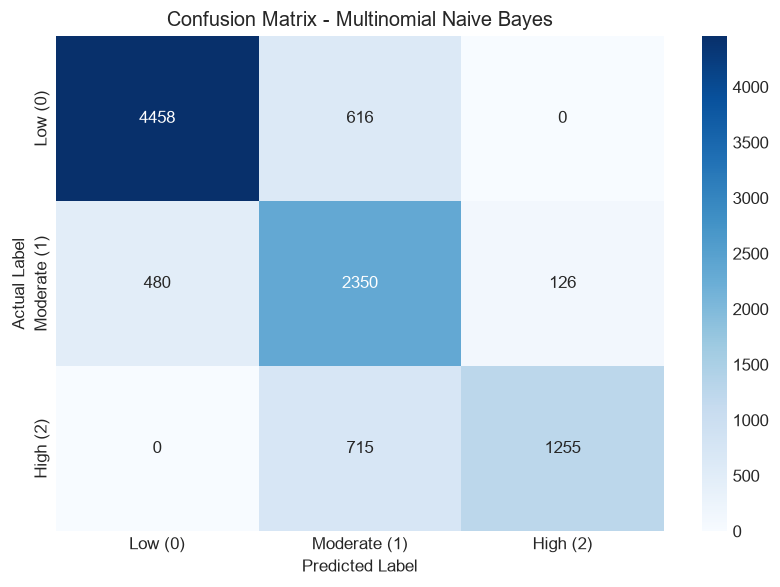

In [18]:
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=target_names,
    yticklabels=target_names
)
plt.title('Confusion Matrix - Multinomial Naive Bayes')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.savefig(
    f'{OUTPUT_DIR}/confusion_matrix_multinomial.png'
)
plt.show()

### 5.2 Visualisasi Distribusi Kelas Prediksi vs Aktual

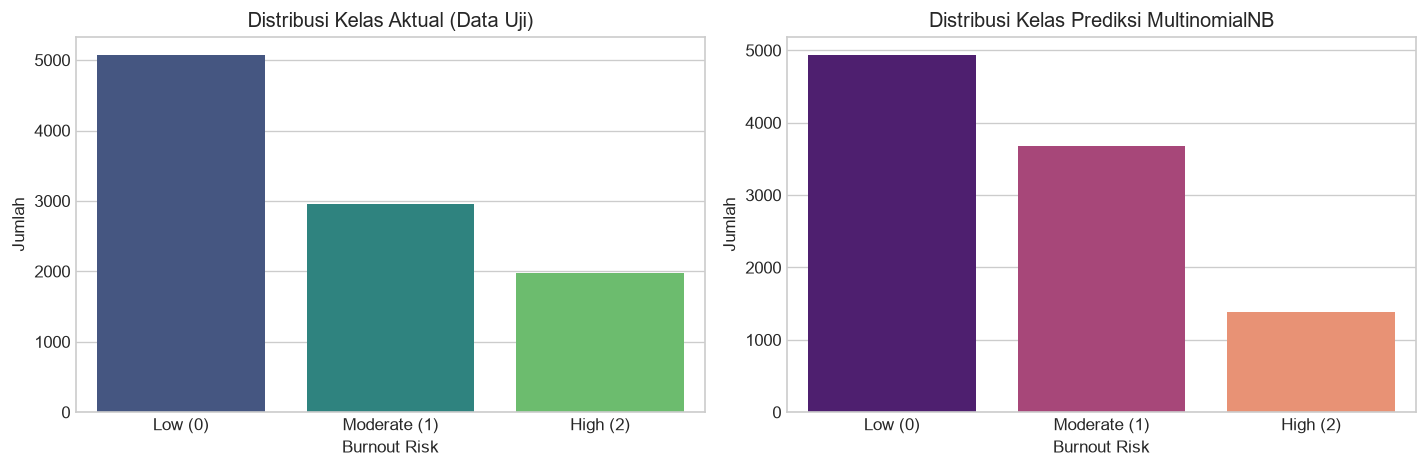

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(
    x=y_test,
    ax=axes[0],
    palette='viridis'
)
axes[0].set_title('Distribusi Kelas Aktual (Data Uji)')
axes[0].set_xticklabels(target_names)
axes[0].set_xlabel('Burnout Risk')
axes[0].set_ylabel('Jumlah')

sns.countplot(
    x=y_pred,
    ax=axes[1],
    palette='magma'
)
axes[1].set_title('Distribusi Kelas Prediksi MultinomialNB')
axes[1].set_xticklabels(target_names)
axes[1].set_xlabel('Burnout Risk')
axes[1].set_ylabel('Jumlah')

plt.tight_layout()
plt.savefig(
    f'{OUTPUT_DIR}/distribution_actual_vs_predicted_multinomial.png'
)
plt.show()

### 5.3 Visualisasi Metrik Evaluasi Stratified 5-Fold Cross-Validation

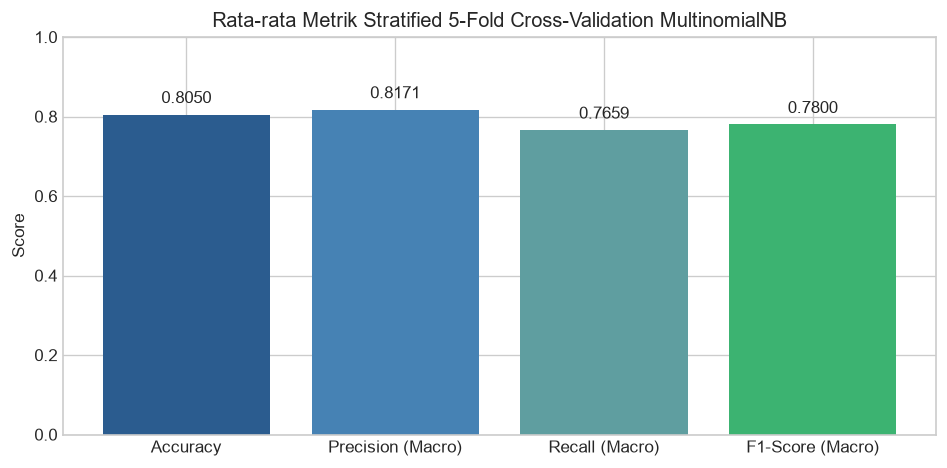

In [20]:
metrics_cv = ['Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'F1-Score (Macro)']
cv_means = [
    cv_results['test_accuracy'].mean(),
    cv_results['test_precision_macro'].mean(),
    cv_results['test_recall_macro'].mean(),
    cv_results['test_f1_macro'].mean()
]

plt.figure(figsize=(8, 4))
bars = plt.bar(
    metrics_cv,
    cv_means,
    color=['#2b5c8f', '#4682b4', '#5f9ea0', '#3cb371']
)
plt.title('Rata-rata Metrik Stratified 5-Fold Cross-Validation MultinomialNB')
plt.ylabel('Score')
plt.ylim(0, 1)

for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        yval + 0.02,
        f'{yval:.4f}',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.savefig(
    f'{OUTPUT_DIR}/cv_metrics_multinomial.png'
)
plt.show()

## 6. Analisis

### 6.1 Analisis Prior Probabilitas dan Log Probabilitas Fitur (Feature Log Prob)

In [21]:
df_priors = pd.DataFrame(
    {
        'Kelas': target_names,
        'Prior_Probability': [round(p, 4) for p in model.class_log_prior_]
    }
)

df_log_prob = pd.DataFrame(
    model.feature_log_prob_,
    columns=X.columns,
    index=target_names
)

print('Log Prior Probability per Kelas:')
display(df_priors)
print('\nFeature Log Probability per Kelas (10 Fitur Pertama):')
df_log_prob.T.head(10)

Log Prior Probability per Kelas:


,Kelas,Prior_Probability
0,Low (0),-0.6785
1,Moderate (1),-1.2187
2,High (2),-1.6244



Feature Log Probability per Kelas (10 Fitur Pertama):


,Low (0),Moderate (1),High (2)
Age,-3.344492,-3.375344,-3.440604
Monthly_Income_USD,-3.339588,-3.379398,-3.434275
Work_Hours_Per_Week,-3.706650,-3.218289,-3.027324
Job_Satisfaction,-3.340091,-3.384726,-3.438166
Work_Life_Balance,-3.340141,-3.381315,-3.432654
Sleep_Hours,-3.249276,-3.426649,-3.644050
Anxiety_Score,-4.212938,-3.366775,-3.026115
Depression_Score,-4.203787,-3.366326,-3.025187
Mood_Score,-2.887164,-3.379485,-4.124551
Emotional_Stability,-2.884060,-3.388066,-4.171710


### 6.2 Visualisasi 10 Fitur Paling Berpengaruh pada MultinomialNB

<Figure size 1440x720 with 0 Axes>

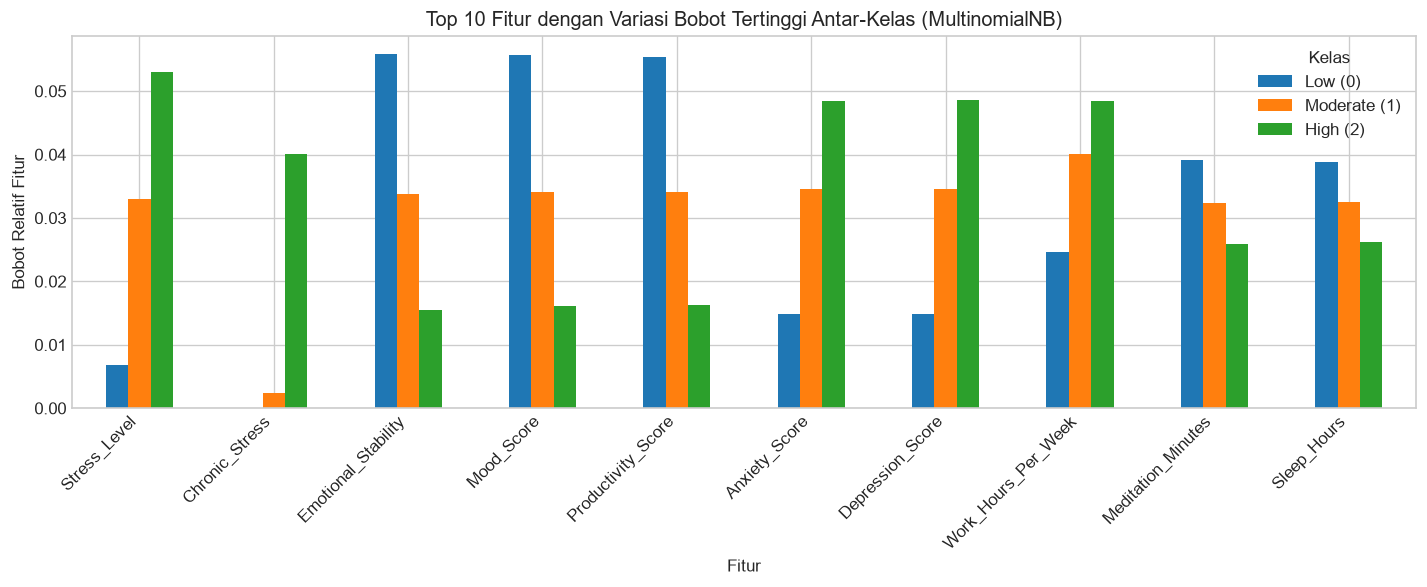

In [22]:
df_prob = pd.DataFrame(
    np.exp(model.feature_log_prob_),
    columns=X.columns,
    index=target_names
)

plt.figure(figsize=(12, 6))
top_diff = df_prob.std().sort_values(ascending=False).head(10)
df_prob[top_diff.index].T.plot(kind='bar', figsize=(12, 5))
plt.title('Top 10 Fitur dengan Variasi Bobot Tertinggi Antar-Kelas (MultinomialNB)')
plt.ylabel('Bobot Relatif Fitur')
plt.xlabel('Fitur')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Kelas')
plt.tight_layout()
plt.savefig(
    f'{OUTPUT_DIR}/top_feature_probabilities_multinomial.png'
)
plt.show()

## 7. Ekspor File

### 7.1 Ekspor Ringkasan Evaluasi

In [23]:
evaluation_result.to_csv(
    f'{OUTPUT_DIR}/metrics_nb_multinomial.csv',
    index=False
)

### 7.2 Ekspor Hasil Prediksi Data Uji

In [24]:
df_prediksi.to_csv(
    f'{OUTPUT_DIR}/predictions_nb_multinomial.csv'
)

### 7.3 Ekspor Hasil 5-Fold Cross-Validation

In [25]:
df_cv.to_csv(
    f'{OUTPUT_DIR}/cv_5fold_nb_multinomial.csv'
)